# Résultats : petits agents collaboratifs vs grand agent

Ce notebook lit un dossier produit par `run_experiment.py` (`results/<date>_<nom>/`) et affiche :

1. la configuration de l'expérience ;
2. le tableau de synthèse (médiane et quantiles 5 % / 95 % sur les graines) ;
3. l'accuracy de test par méthode et par agent ;
4. les courbes d'apprentissage ;
5. la calibration (diagramme de fiabilité) ;
6. la diversité des petits agents et l'accuracy par classe.

Il suffit de régler `RUN_DIR` ci-dessous (par défaut : le run le plus récent) puis *Run All*.

In [ ]:
import glob
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import Markdown, display

# --- À régler -------------------------------------------------------------
RESULTS_ROOT = "results"   # dossier contenant les runs
RUN_DIR = None             # None = run le plus récent ; sinon "results/20261019-083821_collab_vs_big"
CODE_DIR = "."             # dossier du code (pour recharger les labels de test via data.py)
# ---------------------------------------------------------------------------

if RUN_DIR is None:
    def is_collab_vs_big(d):   # runs avec au moins une graine finie, hors balayages de alpha
        try:
            with open(os.path.join(d, "results.json")) as f:
                return json.load(f).get("experiment") != "alpha_sweep"
        except (FileNotFoundError, json.JSONDecodeError):
            return False
    runs = sorted(d for d in glob.glob(os.path.join(RESULTS_ROOT, "*")) if is_collab_vs_big(d))
    if not runs:
        raise FileNotFoundError(f"Aucun run dans {os.path.abspath(RESULTS_ROOT)}")
    RUN_DIR = runs[-1]

with open(os.path.join(RUN_DIR, "config.json")) as f:
    config = json.load(f)
with open(os.path.join(RUN_DIR, "results.json")) as f:
    results = json.load(f)

runs = results["runs"]
seeds = [r["seed"] for r in runs]
sizes = results["model_sizes"]
probs_small = {s: np.load(os.path.join(RUN_DIR, "probs", f"small_agents_s{s}.npy")) for s in seeds}
probs_big = {s: np.load(os.path.join(RUN_DIR, "probs", f"big_agent_s{s}.npy")) for s in seeds}
print(f"Run : {os.path.abspath(RUN_DIR)}  |  graines terminées : {seeds}")

Run : c:\Users\jketchak\Documents\DALPHAcommunity\UNAMUR\EUREKA\btwg_ml\MultiAgentsAI\results\20261019-150406_collab_vs_big  |  graines terminées : [0, 1, 2]


In [ ]:
# --- Style commun des figures ----------------------------------------------
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BIG = "#eb6834"      # grand agent seul
CONS = "#2a78d6"     # consensus des petits agents
AGENT = "#b5b3ab"    # petits agents individuels (contexte)
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2, "lines.solid_capstyle": "round",
})

FIG_DIR = os.path.join(RUN_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"))

K = config["num_agents"]
Q_LO, Q_HI = 0.05, 0.95   # quantiles affichés partout avec la médiane

def stats(values, axis=None):
    """Médiane, quantile 5 % et quantile 95 % (sur les graines)."""
    v = np.asarray(values, dtype=float)
    return np.median(v, axis=axis), np.quantile(v, Q_LO, axis=axis), np.quantile(v, Q_HI, axis=axis)
SMALL = f"{K} × {config['small_arch']}"
BIG_LABEL = f"Grand {config['small_arch']} (×{sizes['big_width']:.2f})"

## 1. Configuration

In [ ]:
rows = {
    "Jeu de données": config["dataset"],
    "Petits agents": f"{K} × {config['small_arch']}  ({sizes['small_params_each']:,} param. chacun, {sizes['small_params_total']:,} au total)",
    "Grand agent": f"{config['small_arch']} largeur ×{sizes['big_width']}  ({sizes['big_params']:,} param., écart {sizes['params_relative_gap']:+.2%})",
    "Loss des petits agents": f"{config['loss_type']} + {config['strategy']}  (α = {config['alpha']}, τ = {config['temperature']})",
    "Loss du grand agent": "cross-entropy",
    "Optimiseur (petits)": f"{config['optimizer']}, lr = {config['lr']}",
    "Optimiseur (grand)": f"{config.get('big_optimizer') or config['optimizer']}, lr = {config.get('big_lr') or config['lr']}",
    "Entraînement": f"{config['epochs']} epochs (warmup {config['warmup_epochs']}), batch {config['batch_size']}, weight decay {config['weight_decay']}, augmentation : {config['augment']}",
    "Validation / sous-ensemble": f"val_size = {config['val_size']}, train_subset = {config['train_subset']}",
    "Graines": ", ".join(map(str, seeds)),
    "Matériel": f"{config.get('device', '?')}, précision {config['precision']}",
    "Durée d'entraînement": f"{results['train_time_s'] / 60:.1f} min",
}
display(pd.DataFrame({"": list(rows.values())}, index=list(rows.keys()))
        .style.set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("font-weight", "600")]}]))

,
Jeu de données,cifar10
Petits agents,"3 × resnet20 (272,474 param. chacun, 817,422 au total)"
Grand agent,"resnet20 largeur ×1.7344 (820,347 param., écart +0.36%)"
Loss des petits agents,"global_interaction + simplicial (α = 1.0, τ = 1.0)"
Loss du grand agent,cross-entropy
Optimiseur (petits),"sgd, lr = 0.001"
Optimiseur (grand),"sgd, lr = 0.001"
Entraînement,"10 epochs (warmup 5), batch 128, weight decay 0.0005, augmentation : True"
Validation / sous-ensemble,"val_size = 10000, train_subset = None"
Graines,"0, 1, 2"


## 2. Tableau de synthèse

Médiane [quantile 5 % ; quantile 95 %] sur les graines. En gras : la meilleure médiane de chaque colonne (accuracy la plus haute, NLL et ECE les plus basses).

Avec peu de graines, les quantiles 5 % et 95 % sont proches du minimum et du maximum.

In [ ]:
sa = lambda r: r["small_agents"]
# Valeurs par graine, recalculées depuis les runs (fonctionne aussi avec les anciens results.json)
per_seed = {
    "Grand agent seul": {
        "acc": [r["big_agent"]["accuracy"] for r in runs],
        "nll": [r["big_agent"]["nll"] for r in runs],
        "ece": [r["big_agent"]["ece"] for r in runs]},
    "Consensus des petits agents": {
        "acc": [sa(r)["accuracy_consensus"] for r in runs],
        "nll": [sa(r)["nll_consensus"] for r in runs],
        "ece": [sa(r)["ece_consensus"] for r in runs]},
    "Moyenne simple des petits": {"acc": [sa(r)["accuracy_mean_ensemble"] for r in runs]},
    "Petit agent (médiane)": {
        "acc": [np.median(sa(r)["accuracy_agents"]) for r in runs],
        "nll": [np.median(sa(r)["nll_agents"]) for r in runs],
        "ece": [np.median(sa(r)["ece_agents"]) for r in runs]},
    "Meilleur petit agent": {"acc": [max(sa(r)["accuracy_agents"]) for r in runs]},
}
per_seed = {m: {k: [v for v in vals if v is not None] for k, vals in d.items()} for m, d in per_seed.items()}

def cell(values, pct=False):
    if not values:
        return "–"
    med, lo, hi = stats(np.array(values) * (100 if pct else 1))
    return f"{med:.2f} [{lo:.2f} ; {hi:.2f}]" if pct else f"{med:.4f} [{lo:.4f} ; {hi:.4f}]"

cols = {"Accuracy (%)": ("acc", True), "NLL": ("nll", False), "ECE": ("ece", False)}
table = pd.DataFrame({c: {m: cell(d.get(k), pct) for m, d in per_seed.items()} for c, (k, pct) in cols.items()})
medians = pd.DataFrame({c: {m: np.median(d[k]) if d.get(k) else np.nan for m, d in per_seed.items()}
                        for c, (k, _) in cols.items()})
best = {"Accuracy (%)": medians["Accuracy (%)"].idxmax(), "NLL": medians["NLL"].idxmin(), "ECE": medians["ECE"].idxmin()}

def highlight(col):
    return ["font-weight: 700" if idx == best[col.name] else "" for idx in col.index]

display(table.style.apply(highlight)
        .set_properties(**{"text-align": "right", "font-variant-numeric": "tabular-nums"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

gaps = (np.array(per_seed["Consensus des petits agents"]["acc"]) - np.array(per_seed["Grand agent seul"]["acc"])) * 100
med, lo, hi = stats(gaps)
display(Markdown(f"**Écart consensus − grand agent (par graine) : médiane {med:+.2f} points "
                 f"[{lo:+.2f} ; {hi:+.2f}].**"))

,Accuracy (%),NLL,ECE
Grand agent seul,55.00 [53.62 ; 55.24],1.2419 [1.2324 ; 1.2665],0.0139 [0.0124 ; 0.0180]
Consensus des petits agents,70.00 [69.52 ; 70.41],0.9068 [0.9041 ; 0.9170],0.1381 [0.1368 ; 0.1396]
Moyenne simple des petits,70.15 [69.66 ; 70.50],–,–
Petit agent (médiane),66.95 [66.60 ; 67.02],0.9588 [0.9516 ; 0.9654],0.1028 [0.1016 ; 0.1034]
Meilleur petit agent,67.18 [66.89 ; 67.47],–,–


**Écart consensus − grand agent (par graine) : médiane +15.45 points [+14.33 ; +16.42].**

## 3. Accuracy de test

Barres : médiane sur les graines ; trait : quantiles 5 %–95 % ; points : chaque graine.

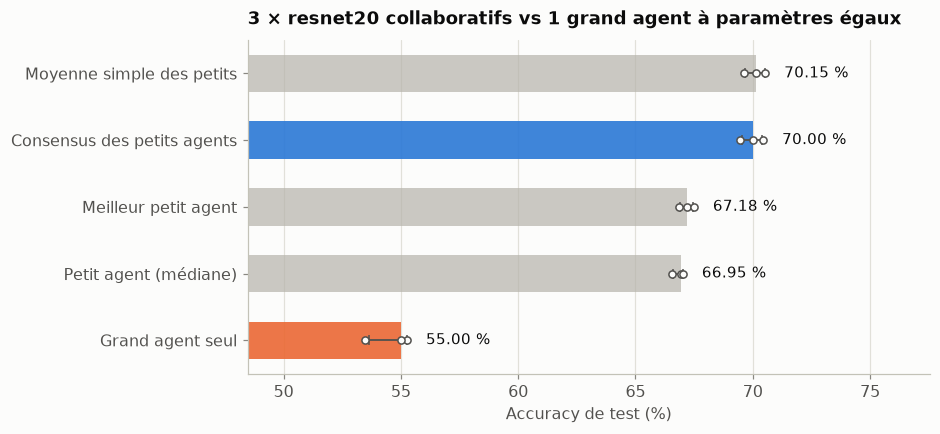

In [ ]:
colors = {"Grand agent seul": BIG, "Consensus des petits agents": CONS}
order = sorted(per_seed, key=lambda m: np.median(per_seed[m]["acc"]))
fig, ax = plt.subplots(figsize=(8, 0.55 * len(order) + 1.2))
for i, m in enumerate(order):
    vals = np.array(per_seed[m]["acc"]) * 100
    med, lo, hi = stats(vals)
    c = colors.get(m, AGENT)
    ax.barh(i, med, height=0.56, color=c, alpha=0.9 if m in colors else 0.7, zorder=2)
    if len(vals) > 1:
        ax.errorbar(med, i, xerr=[[med - lo], [hi - med]], color=INK2, lw=1.2, capsize=3, zorder=3)
    ax.scatter(vals, np.full(len(vals), i), s=22, color=SURFACE, edgecolor=INK2, lw=1, zorder=4)
    ax.text(max(vals.max(), hi) + 0.8, i, f"{med:.2f} %", va="center", color=INK, fontsize=10)
ax.set_yticks(range(len(order)), order)
all_acc = np.concatenate([d["acc"] for d in per_seed.values()]) * 100
ax.set_xlim(max(0, all_acc.min() - 5), min(104, all_acc.max() + 7))
ax.set_xlabel("Accuracy de test (%)")
ax.grid(axis="y", visible=False)
ax.set_title(f"{SMALL} collaboratifs vs 1 grand agent à paramètres égaux")
save(fig, "accuracy_methodes"); plt.show()

### Accuracy de chaque petit agent

Chaque point est un petit agent, une colonne par graine. Lignes : consensus (bleu) et grand agent (orange) de la même graine.

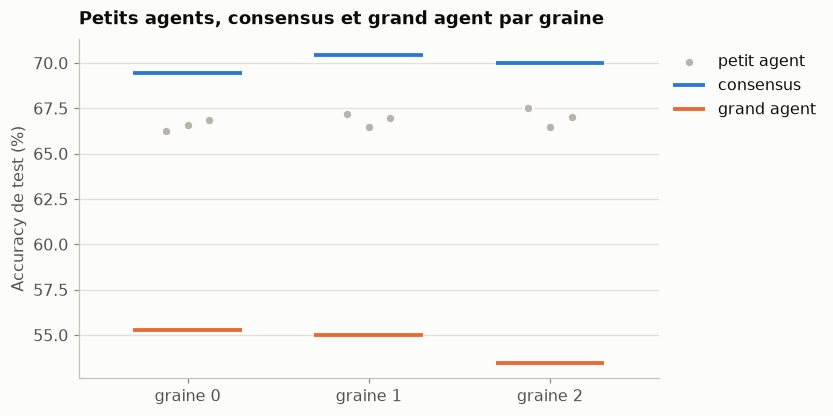

In [ ]:
fig, ax = plt.subplots(figsize=(max(5, 1.6 * len(runs) + 2), 4))
for j, r in enumerate(runs):
    accs = np.array(r["small_agents"]["accuracy_agents"]) * 100
    jitter = np.linspace(-0.12, 0.12, len(accs))
    ax.scatter(j + jitter, accs, s=40, color=AGENT, edgecolor=SURFACE, lw=1.5, zorder=3,
               label="petit agent" if j == 0 else None)
    ax.hlines(r["small_agents"]["accuracy_consensus"] * 100, j - 0.3, j + 0.3, color=CONS, lw=2.5, zorder=4,
              label="consensus" if j == 0 else None)
    ax.hlines(r["big_agent"]["accuracy"] * 100, j - 0.3, j + 0.3, color=BIG, lw=2.5, zorder=4,
              label="grand agent" if j == 0 else None)
ax.set_xticks(range(len(runs)), [f"graine {s}" for s in seeds])
ax.set_xlim(-0.6, len(runs) - 0.4)
ax.set_ylabel("Accuracy de test (%)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Petits agents, consensus et grand agent par graine")
save(fig, "accuracy_agents"); plt.show()

## 4. Courbes d'apprentissage

Médiane sur les graines (bande : quantiles 5 %–95 %). Pour les petits agents, `accuracy` est celle du consensus ; les agents individuels sont en gris. Les losses ne sont pas comparées entre elles : la loss multiplicative des petits agents et la cross-entropy du grand agent n'ont pas la même échelle.

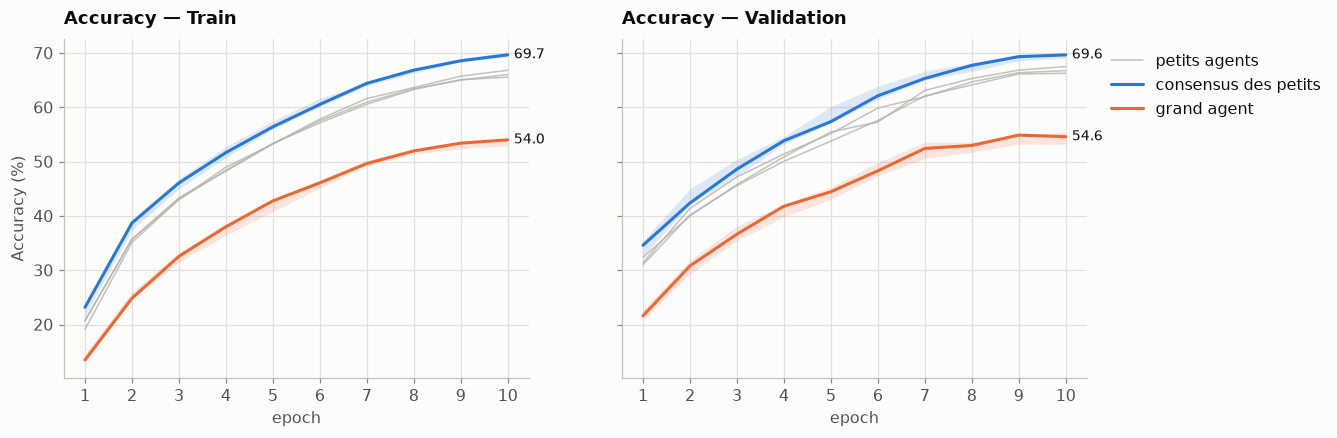

In [ ]:
def curves(key, who):
    hs = [r["small_agents" if who == "small" else "big_agent"]["history"] for r in runs]
    if not all(key in h for h in hs):
        return None
    return np.array([h[key] for h in hs]) * 100

panels = [("accuracy", "Train"), ("val_accuracy", "Validation")]
panels = [p for p in panels if curves(p[0], "small") is not None]
fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 4), sharey=True, squeeze=False)
for ax, (key, title) in zip(axes[0], panels):
    for k in range(1, K + 1):
        a = curves(f"{key}_agent{k}", "small")
        if a is not None:
            ax.plot(np.arange(1, a.shape[1] + 1), np.median(a, 0), color=AGENT, lw=1, alpha=0.8,
                    label="petits agents" if k == 1 else None)
    for who, color, label in [("small", CONS, "consensus des petits"), ("big", BIG, "grand agent")]:
        a = curves(key, who)
        x = np.arange(1, a.shape[1] + 1)
        med, lo, hi = stats(a, axis=0)
        ax.fill_between(x, lo, hi, color=color, alpha=0.15, lw=0)
        ax.plot(x, med, color=color, label=label)
        ax.annotate(f"{med[-1]:.1f}", (x[-1], med[-1]), xytext=(4, 0), textcoords="offset points",
                    va="center", color=INK, fontsize=9)
    ax.set_title(f"Accuracy — {title}")
    ax.set_xlabel("epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0][0].set_ylabel("Accuracy (%)")
axes[0][-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
save(fig, "courbes_accuracy"); plt.show()

## 5. Calibration

Un modèle bien calibré a une confiance égale à son accuracy (diagonale). Les barres sous l'axe indiquent combien d'exemples tombent dans chaque tranche de confiance. Nécessite les labels de test, rechargés avec `data.load_dataset` (même découpage que l'expérience).

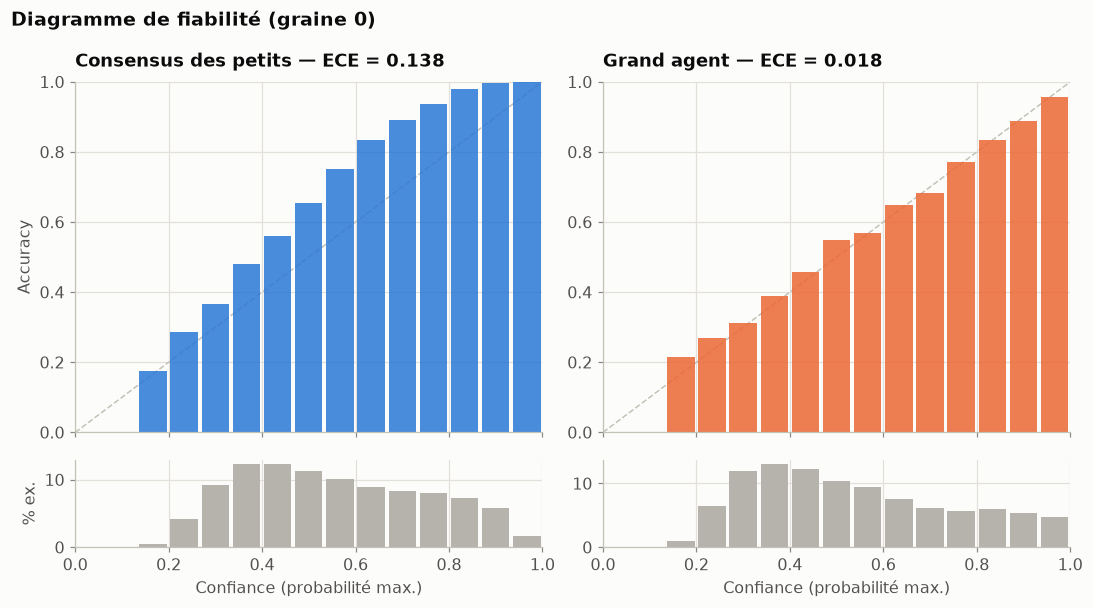

In [ ]:
sys.path.insert(0, os.path.abspath(CODE_DIR))
from data import load_dataset

y_test = load_dataset(config["dataset"], val_size=config["val_size"], seed=0)["y_test"].reshape(-1)

def simplicial_consensus(p, tau):
    """Même consensus que MultiAgentModel : w_k = softmax(-H_k / tau), y = Σ w_k p_k."""
    H = -(p * np.log(np.clip(p, 1e-12, 1))).sum(-1)          # (N, K)
    z = -H / tau
    w = np.exp(z - z.max(1, keepdims=True)); w /= w.sum(1, keepdims=True)
    return (w[..., None] * p).sum(1)

def consensus_probs(p):
    if config["strategy"] == "simplicial":
        return simplicial_consensus(p, config["temperature"])
    return p.mean(1)   # stratégies à labels durs : moyenne des probabilités

def reliability(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(conf, bins) - 1, 0, n_bins - 1)
    acc = np.array([(pred[idx == b] == y[idx == b]).mean() if (idx == b).any() else np.nan for b in range(n_bins)])
    cnt = np.bincount(idx, minlength=n_bins)
    ece = np.nansum(np.abs(acc - np.array([conf[idx == b].mean() if (idx == b).any() else 0 for b in range(n_bins)])) * cnt) / len(y)
    return bins, acc, cnt, ece

s0 = seeds[0]
items = [("Consensus des petits", consensus_probs(probs_small[s0]), CONS), ("Grand agent", probs_big[s0], BIG)]
fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [4, 1]})
for col, (name, p, color) in enumerate(items):
    bins, acc, cnt, ece = reliability(p, y_test)
    centers, width = (bins[:-1] + bins[1:]) / 2, bins[1] - bins[0]
    ax = axes[0, col]
    ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--", zorder=1)
    ax.bar(centers, acc, width=width - 0.008, color=color, alpha=0.85, zorder=2)
    ax.set_title(f"{name} — ECE = {ece:.3f}")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_ylabel("Accuracy" if col == 0 else "")
    axes[1, col].bar(centers, cnt / cnt.sum() * 100, width=width - 0.008, color=AGENT, zorder=2)
    axes[1, col].set_xlabel("Confiance (probabilité max.)")
    axes[1, col].set_ylabel("% ex." if col == 0 else "")
fig.suptitle(f"Diagramme de fiabilité (graine {s0})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "calibration"); plt.show()

## 6. Diversité des petits agents

Pourcentage d'exemples de test sur lesquels deux agents prédisent une classe différente. Plus c'est haut, plus les agents sont divers ; une collaboration trop forte peut les rendre identiques.

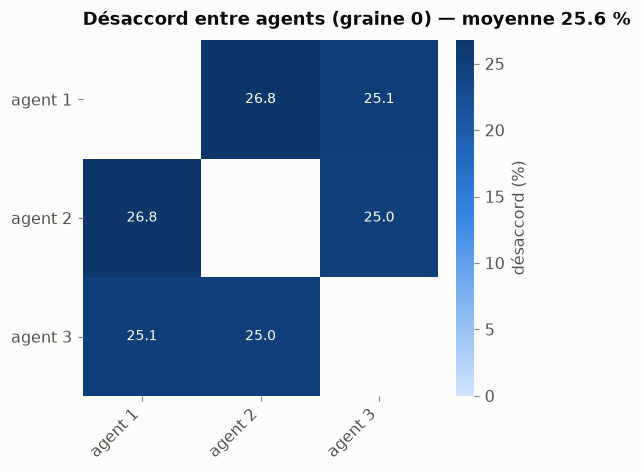

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blues", BLUES)

preds = probs_small[s0].argmax(-1)                          # (N, K)
D = np.array([[(preds[:, i] != preds[:, j]).mean() * 100 for j in range(K)] for i in range(K)])
fig, ax = plt.subplots(figsize=(1.0 * K + 2.2, 1.0 * K + 1.2))
cmap.set_bad(SURFACE)
im = ax.imshow(np.where(np.eye(K, dtype=bool), np.nan, D), cmap=cmap, vmin=0, vmax=max(D.max(), 1))
for i in range(K):
    for j in range(K):
        if i != j:
            ax.text(j, i, f"{D[i, j]:.1f}", ha="center", va="center", fontsize=9,
                    color="white" if D[i, j] > 0.6 * D.max() else INK)
labels = [f"agent {k + 1}" for k in range(K)]
ax.set_xticks(range(K), labels, rotation=45, ha="right"); ax.set_yticks(range(K), labels)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.outline.set_visible(False)
cb.set_label("désaccord (%)", color=INK2)
off = D[~np.eye(K, dtype=bool)]
ax.set_title(f"Désaccord entre agents (graine {s0}) — moyenne {off.mean():.1f} %")
save(fig, "diversite"); plt.show()

## 7. Accuracy par classe

Médiane sur les graines (trait : quantiles 5 %–95 %). Utile pour voir sur quelles classes la collaboration aide ou pénalise.

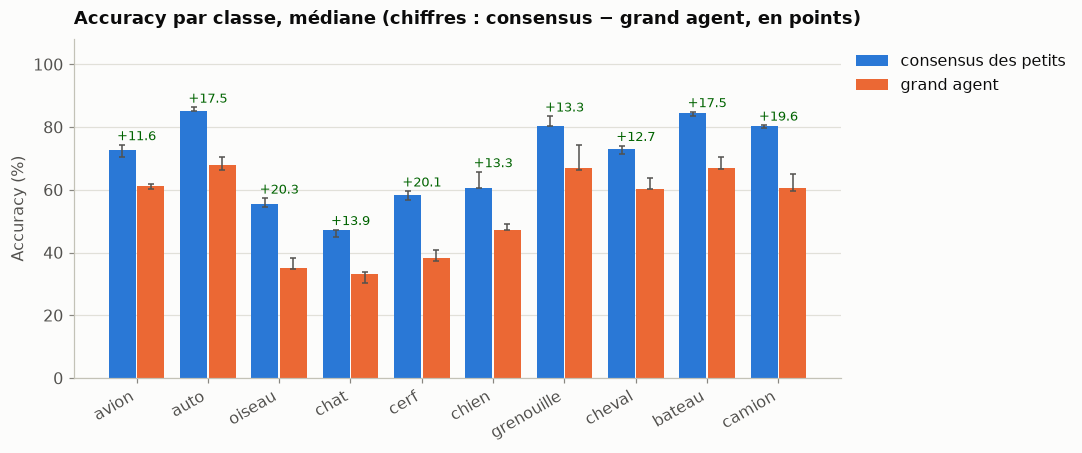

In [ ]:
CLASS_NAMES = {
    "cifar10": ["avion", "auto", "oiseau", "chat", "cerf", "chien", "grenouille", "cheval", "bateau", "camion"],
    "fashion_mnist": ["T-shirt", "pantalon", "pull", "robe", "manteau", "sandale", "chemise", "basket", "sac", "bottine"],
}
n_cls = probs_big[s0].shape[-1]
names = CLASS_NAMES.get(config["dataset"], [str(c) for c in range(n_cls)])

def per_class(probs):
    pred = probs.argmax(1)
    return np.array([(pred[y_test == c] == c).mean() * 100 for c in range(n_cls)])

cons_all = np.array([per_class(consensus_probs(probs_small[s])) for s in seeds])
big_all = np.array([per_class(probs_big[s]) for s in seeds])
acc_cons, cons_lo, cons_hi = stats(cons_all, axis=0)
acc_big, big_lo, big_hi = stats(big_all, axis=0)

x = np.arange(n_cls); w = 0.38
fig, ax = plt.subplots(figsize=(max(8, 0.9 * n_cls), 4))
ax.bar(x - w / 2 - 0.01, acc_cons, w, color=CONS, label="consensus des petits", zorder=2)
ax.bar(x + w / 2 + 0.01, acc_big, w, color=BIG, label="grand agent", zorder=2)
if len(seeds) > 1:
    ax.errorbar(x - w / 2 - 0.01, acc_cons, yerr=[acc_cons - cons_lo, cons_hi - acc_cons], fmt="none", ecolor=INK2, lw=1, capsize=2, zorder=3)
    ax.errorbar(x + w / 2 + 0.01, acc_big, yerr=[acc_big - big_lo, big_hi - acc_big], fmt="none", ecolor=INK2, lw=1, capsize=2, zorder=3)
for xi, d in zip(x, acc_cons - acc_big):
    ax.text(xi, max(cons_hi[xi], big_hi[xi]) + 1.5, f"{d:+.1f}", ha="center", fontsize=8.5,
            color="#006300" if d > 0 else INK2)
ax.set_xticks(x, names, rotation=30, ha="right")
ax.set_ylabel("Accuracy (%)"); ax.set_ylim(0, 108)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Accuracy par classe, médiane (chiffres : consensus − grand agent, en points)")
save(fig, "accuracy_par_classe"); plt.show()

## 8. Comparer plusieurs runs

Toutes les expériences de `RESULTS_ROOT` sur une ligne chacune (médianes sur les graines).

In [ ]:
rows = []
for d in sorted(glob.glob(os.path.join(RESULTS_ROOT, "*"))):
    try:
        cfg = json.load(open(os.path.join(d, "config.json")))
        res = json.load(open(os.path.join(d, "results.json")))
    except FileNotFoundError:
        continue
    if res.get("experiment") == "alpha_sweep":   # voir resultats_sweep.ipynb
        continue
    r_ = res["runs"]
    rows.append({
        "run": os.path.basename(d), "dataset": cfg["dataset"],
        "agents": f"{cfg['num_agents']} × {cfg['small_arch']}", "loss": f"{cfg['loss_type']}+{cfg['strategy']}",
        "epochs": cfg["epochs"], "graines": len(res["runs"]),
        "consensus (%)": np.median([x["small_agents"]["accuracy_consensus"] for x in r_]) * 100,
        "grand agent (%)": np.median([x["big_agent"]["accuracy"] for x in r_]) * 100,
    })
df = pd.DataFrame(rows).set_index("run")
df["écart (pts)"] = df["consensus (%)"] - df["grand agent (%)"]
display(df.style.format({"consensus (%)": "{:.2f}", "grand agent (%)": "{:.2f}", "écart (pts)": "{:+.2f}"})
        .bar(subset=["écart (pts)"], align="zero", color=[BIG + "66", CONS + "66"]))
print(f"Figures enregistrées dans {os.path.abspath(FIG_DIR)}")

,dataset,agents,loss,epochs,graines,consensus (%),grand agent (%),écart (pts)
run,,,,,,,,
20261019-114342_collab_vs_big,cifar10,3 × resnet20,global_interaction+simplicial,10,3,69.93,54.72,+15.21
20261019-135636_collab_vs_big,cifar10,3 × resnet20,global_interaction+simplicial,10,3,69.91,55.02,+14.89
20261019-141551_collab_vs_big,cifar10,3 × resnet20,global_interaction+simplicial,10,3,62.08,54.62,+7.46
20261019-144421_collab_vs_big,cifar10,3 × resnet20,global_interaction+simplicial,10,3,61.55,54.43,+7.12
20261019-150406_collab_vs_big,cifar10,3 × resnet20,global_interaction+simplicial,10,3,70.00,55.00,+15.00


Figures enregistrées dans c:\Users\jketchak\Documents\DALPHAcommunity\UNAMUR\EUREKA\btwg_ml\MultiAgentsAI\results\20261019-150406_collab_vs_big\figures
